# Задание 3. Рекуррентные сети (LSTM и GRU)

In [6]:
import os, re, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score, accuracy_score, classification_report, ConfusionMatrixDisplay

SEED = 42
keras.utils.set_random_seed(SEED)
os.makedirs("../results", exist_ok=True)

# настройки
TRAIN_PATH, TEST_PATH = "../data/train.parquet", "../data/test.parquet"
TEXT_COL, LABEL_COL = "CONTENT_edited", "class"
VOCAB = 20000        # размер словаря
EPOCHS = 30          # максимум эпох
BATCH = 64
PREPROC = "clean+typos+lemma+slang"    
USE_CLASS_WEIGHT = True

In [7]:
def clean(text):
    return str(text)

train_df = pd.read_parquet(TRAIN_PATH).dropna(subset=[TEXT_COL, LABEL_COL])
test_df = pd.read_parquet(TEST_PATH).dropna(subset=[TEXT_COL, LABEL_COL])

le = LabelEncoder().fit(train_df[LABEL_COL])
N_CLASSES = len(le.classes_)

X_text = train_df[TEXT_COL].map(clean).astype(str).to_numpy()
y = le.transform(train_df[LABEL_COL])
X_test_text = test_df[TEXT_COL].map(clean).astype(str).to_numpy()
y_test = le.transform(test_df[LABEL_COL])

X_tr_text, X_val_text, y_tr, y_val = train_test_split(
    X_text, y, test_size=0.15, stratify=y, random_state=SEED)

print("train/val/test:", len(y_tr), len(y_val), len(y_test), "| классов:", N_CLASSES)
print(pd.Series(le.inverse_transform(y_tr)).value_counts())

train/val/test: 449 80 59 | классов: 8
1    221
5    118
6     32
3     22
4     21
2     19
8     12
7      4
Name: count, dtype: int64


In [8]:
# длина последовательности
lengths = [len(t.split()) for t in X_tr_text]
MAXLEN = int(min(np.percentile(lengths, 95), 300))
print("MAXLEN =", MAXLEN)

vectorizer = layers.TextVectorization(max_tokens=VOCAB, output_sequence_length=MAXLEN)
vectorizer.adapt(X_tr_text)

def vec(texts):
    return vectorizer(np.array(texts, dtype=str)).numpy()

X_tr, X_val, X_test = vec(X_tr_text), vec(X_val_text), vec(X_test_text)
Y_tr = keras.utils.to_categorical(y_tr, N_CLASSES)
Y_val = keras.utils.to_categorical(y_val, N_CLASSES)

if USE_CLASS_WEIGHT:
    w = compute_class_weight("balanced", classes=np.arange(N_CLASSES), y=y_tr)
    CLASS_WEIGHT = dict(enumerate(w))
else:
    CLASS_WEIGHT = None

MAXLEN = 34


In [9]:
OPTIMIZERS = {
    "adam":    lambda: keras.optimizers.Adam(1e-3),
    "nadam":   lambda: keras.optimizers.Nadam(1e-3),
    "rmsprop": lambda: keras.optimizers.RMSprop(1e-3),
    "adamw":   lambda: keras.optimizers.AdamW(1e-3),
    "sgd":     lambda: keras.optimizers.SGD(0.05, momentum=0.9),
}
LOSSES = {
    "cce":        lambda: keras.losses.CategoricalCrossentropy(),
    "cce_smooth": lambda: keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    "focal":      lambda: keras.losses.CategoricalFocalCrossentropy(),
}

def build_model(rnn, cfg):
    Cell = layers.LSTM if rnn == "LSTM" else layers.GRU
    inp = keras.Input(shape=(MAXLEN,), dtype="int32")
    x = layers.Embedding(VOCAB, cfg["emb_dim"], mask_zero=True)(inp)
    x = layers.SpatialDropout1D(cfg["dropout"])(x)
    rnn_layer = Cell(cfg["units"])
    if cfg["bidirectional"]:
        rnn_layer = layers.Bidirectional(rnn_layer)
    x = rnn_layer(x)
    x = layers.Dropout(cfg["dropout"])(x)
    x = layers.Dense(cfg["units"], activation=cfg["activation"])(x)
    x = layers.Dropout(cfg["dropout"])(x)
    out = layers.Dense(N_CLASSES, activation="softmax")(x)
    model = keras.Model(inp, out)
    model.compile(optimizer=OPTIMIZERS[cfg["optimizer"]](),
                  loss=LOSSES[cfg["loss"]]())
    return model

def train_model(rnn, cfg, verbose=0):
    keras.utils.set_random_seed(SEED)
    model = build_model(rnn, cfg)
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=4,
                                       restore_best_weights=True)
    hist = model.fit(X_tr, Y_tr, validation_data=(X_val, Y_val),
                     epochs=EPOCHS, batch_size=BATCH, callbacks=[es],
                     class_weight=CLASS_WEIGHT, verbose=verbose)
    return model, hist

In [14]:
VAL_CSV = "../results/task3_val.csv"
cache = {}

def run_experiment(rnn, cfg):
    key = (rnn, json.dumps(cfg, sort_keys=True))
    if key in cache:
        return cache[key]
    model, hist = train_model(rnn, cfg)
    pred = model.predict(X_val, verbose=0).argmax(1)
    row = {
        "model": rnn, "preprocessing": PREPROC, **cfg,
        "epochs": len(hist.history["loss"]),
        "val_f1_macro": f1_score(y_val, pred, average="macro"),
        "val_f1_weighted": f1_score(y_val, pred, average="weighted"),
        "val_accuracy": accuracy_score(y_val, pred),
    }
    pd.DataFrame([row]).to_csv(VAL_CSV, mode="a", index=False,
                               header=not os.path.exists(VAL_CSV))
    keras.backend.clear_session()
    cache[key] = row
    print(f"{rnn} | {json.dumps(cfg)} -> f1_macro={row['val_f1_macro']:.4f}")
    return row

In [15]:
BASE = dict(bidirectional=True, emb_dim=128, units=64, dropout=0.3,
            activation="relu", optimizer="adam", loss="cce")

GRID = {
    "bidirectional": [False, True],
    "emb_dim":    [64, 128, 200, 300],
    "units":      [32, 64, 128, 256],
    "dropout":    [0.0, 0.2, 0.3, 0.5],
    "optimizer":  list(OPTIMIZERS),
    "activation": ["relu", "tanh", "elu", "selu"],
    "loss":       list(LOSSES),
}

best_cfg = {}
for rnn in ["LSTM", "GRU"]:
    cfg = dict(BASE)
    for param, values in GRID.items():
        scores = {v: run_experiment(rnn, {**cfg, param: v})["val_f1_macro"] for v in values}
        cfg[param] = max(scores, key=scores.get)
        print(f"==> {rnn}: лучший {param} = {cfg[param]}\n")
    best_cfg[rnn] = cfg

print(json.dumps(best_cfg, indent=2))

LSTM | {"bidirectional": false, "emb_dim": 128, "units": 64, "dropout": 0.3, "activation": "relu", "optimizer": "adam", "loss": "cce"} -> f1_macro=0.5763
LSTM | {"bidirectional": true, "emb_dim": 128, "units": 64, "dropout": 0.3, "activation": "relu", "optimizer": "adam", "loss": "cce"} -> f1_macro=0.6840
==> LSTM: лучший bidirectional = True

LSTM | {"bidirectional": true, "emb_dim": 64, "units": 64, "dropout": 0.3, "activation": "relu", "optimizer": "adam", "loss": "cce"} -> f1_macro=0.6947
LSTM | {"bidirectional": true, "emb_dim": 200, "units": 64, "dropout": 0.3, "activation": "relu", "optimizer": "adam", "loss": "cce"} -> f1_macro=0.7836
LSTM | {"bidirectional": true, "emb_dim": 300, "units": 64, "dropout": 0.3, "activation": "relu", "optimizer": "adam", "loss": "cce"} -> f1_macro=0.7026
==> LSTM: лучший emb_dim = 200

LSTM | {"bidirectional": true, "emb_dim": 200, "units": 32, "dropout": 0.3, "activation": "relu", "optimizer": "adam", "loss": "cce"} -> f1_macro=0.6992
LSTM | {"bi

In [12]:
# сводка по перебору
val = val = pd.read_csv(VAL_CSV)
for p in GRID:
    print(f"\n--- {p} ---")
    print(val.groupby(["model", p])["val_f1_macro"].max().unstack(0).round(4))


--- bidirectional ---
model             GRU    LSTM
bidirectional                
False          0.3702  0.5763
True           0.7609  0.8052

--- emb_dim ---
model       GRU    LSTM
emb_dim                
64       0.6852  0.6947
128      0.7609  0.6840
200      0.6199  0.8052
300      0.6853  0.7026

--- units ---
model     GRU    LSTM
units                
32     0.7609  0.6992
64     0.7063  0.8052
128    0.6542  0.7131
256    0.6986  0.6831

--- dropout ---
model       GRU    LSTM
dropout                
0.0      0.5128  0.5618
0.2      0.6809  0.6404
0.3      0.7609  0.8052
0.5      0.6364  0.6011

--- optimizer ---
model         GRU    LSTM
optimizer                
adam       0.7609  0.8052
adamw      0.6799  0.7836
nadam      0.6311  0.7494
rmsprop    0.7056  0.7732
sgd        0.5445  0.6007

--- activation ---
model          GRU    LSTM
activation                
elu         0.6890  0.7926
relu        0.7178  0.7836
selu        0.7399  0.6857
tanh        0.7609  0.8052

--- 


===== LSTM =====
              precision    recall  f1-score   support

           1       0.93      0.86      0.89        29
           2       1.00      0.50      0.67         2
           3       0.50      0.67      0.57         3
           4       0.75      1.00      0.86         3
           5       0.88      0.88      0.88        16
           6       0.60      0.75      0.67         4
           7       0.00      0.00      0.00         0
           8       1.00      1.00      1.00         2

    accuracy                           0.85        59
   macro avg       0.71      0.71      0.69        59
weighted avg       0.86      0.85      0.85        59


===== GRU =====
              precision    recall  f1-score   support

           1       0.90      0.93      0.92        29
           2       1.00      0.50      0.67         2
           3       0.50      0.33      0.40         3
           4       1.00      1.00      1.00         3
           5       1.00      0.94      0.97

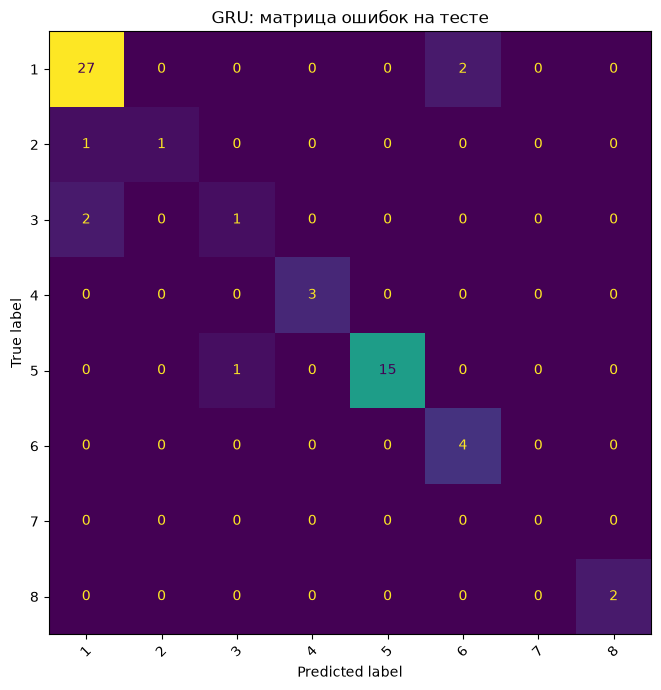

In [13]:
# Финал
TEST_CSV = "../results/task3_test.csv"
final = {}
for rnn, cfg in best_cfg.items():
    model, hist = train_model(rnn, cfg)
    pred = model.predict(X_test, verbose=0).argmax(1)
    row = {"model": rnn, "preprocessing": PREPROC, **cfg,
           "f1_macro": f1_score(y_test, pred, average="macro", labels=np.unique(y_test)),
           "f1_weighted": f1_score(y_test, pred, average="weighted"),
           "accuracy": accuracy_score(y_test, pred)}
    pd.DataFrame([row]).to_csv(TEST_CSV, mode="a", index=False,
                               header=not os.path.exists(TEST_CSV))
    final[rnn] = (row, pred)
    print(f"\n===== {rnn} =====")
    print(classification_report(y_test, pred, labels=np.arange(N_CLASSES), target_names=le.classes_.astype(str), zero_division=0))

best_rnn = max(final, key=lambda k: final[k][0]["f1_macro"])
fig, ax = plt.subplots(figsize=(7, 7))
ConfusionMatrixDisplay.from_predictions(
    y_test, final[best_rnn][1], labels=np.arange(N_CLASSES),
    display_labels=le.classes_.astype(str),
    xticks_rotation=45, ax=ax, colorbar=False)
ax.set_title(f"{best_rnn}: матрица ошибок на тесте")
plt.tight_layout()
plt.savefig("../results/task3_confusion.png", dpi=200)
plt.show()